### OpenCV
- Open Source Computer Vision
- OpenCV란 C언어 기반으로 인텔에서 시작된 프로젝트로 영상처리나 컴퓨터 비전을 위한 라이브러리
- 영상처리, 3D구성, 추적, 기계학습, 인식 그리고 딥러닝 기술 까지 유용한 기능이 많이 들어있는 라이브러리, 상업적인 사용까지도 많이 이용되며 무료로 사용이 가능하다.

### anaconda prompt에 opencv설치
- pip install opencv-python (관리자 권한으로 실행하는걸 추천)

In [3]:

import os

# PaddlePaddle / PaddleX OneDNN 비활성화
os.environ["PADDLE_PDX_ENABLE_MKLDNN_BYDEFAULT"] = "False"
os.environ["PADDLE_PDX_DISABLE_ONEDNN"] = "1"
os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["FLAGS_enable_pir_api"] = "0"

print("OneDNN 비활성화 설정 완료")

OneDNN 비활성화 설정 완료


### anaconda prompt에 opencv설치
- pip install opencv-python (관리자 권한으로 실행하는걸 추천)

In [4]:
!pip install opencv-python

### 이미지 출력
- 실습할 이미지 데이터 다운로드
- https://pixabay.com/ko/images/search/dogs/

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
%cd /content/drive/MyDrive/2026_목포대학교_vision

/content/drive/MyDrive/2026_목포대학교_vision


In [13]:
!pwd

/content/drive/MyDrive/2026_목포대학교_vision


In [6]:
# opencv 도구 불러오기
import cv2
cv2.__version__  # 버전확인

'4.14.0'

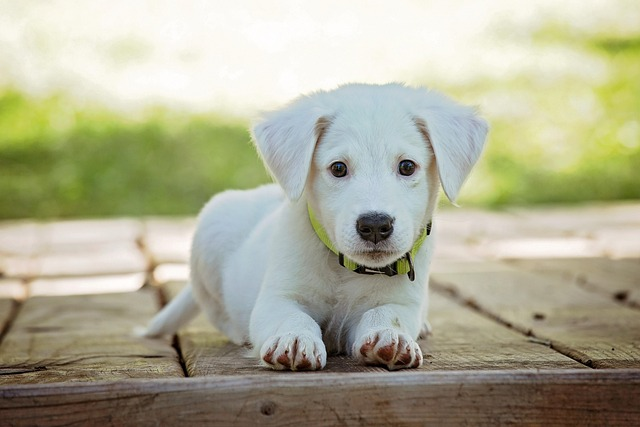

In [7]:
# 구글 코랩에서 opencv 이미지 출력 오류 방지 함수 가져오기
from google.colab.patches import cv2_imshow
# 이미지 처리 및 컴퓨터 비젼 라이브러리
import cv2

# 이미지 출력하기
img = cv2.imread('./data/dog.jpg') # 이미지 불러오기
cv2_imshow(img) # 이미지 보여주기
cv2.waitKey(0)
cv2.destroyAllWindows() # opencv를 사용해서 열린창을 닫는 기능

### imread() 옵션 - 읽기 옵션
- cv2.IMREAD_COLOR : 이미지를 컬러로 업로드(투명도는 무시하고 업로드, 기본값으로 적용)
- cv2.IMREAD_GRAYSCALE : 이미지를 그레이스케일로 업로드
- cv2.IMREAD_UNCHANGED : 이미지를 컬러로 업로드(투명도를 포함하여 업로드)

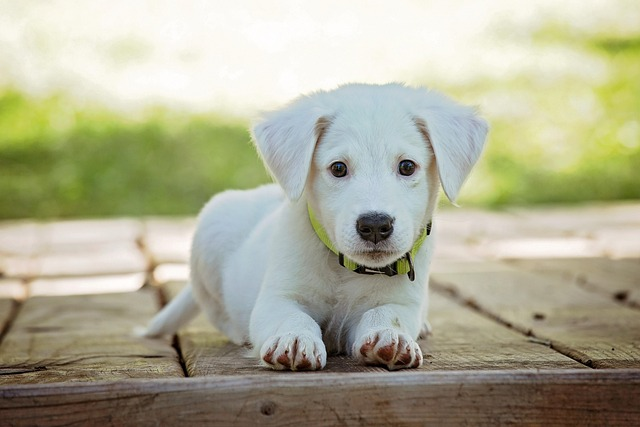

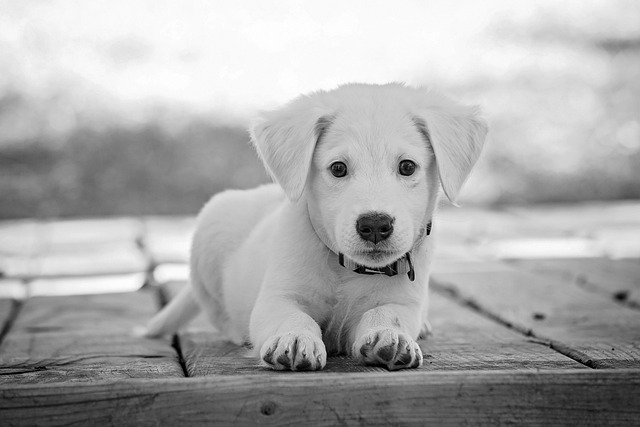

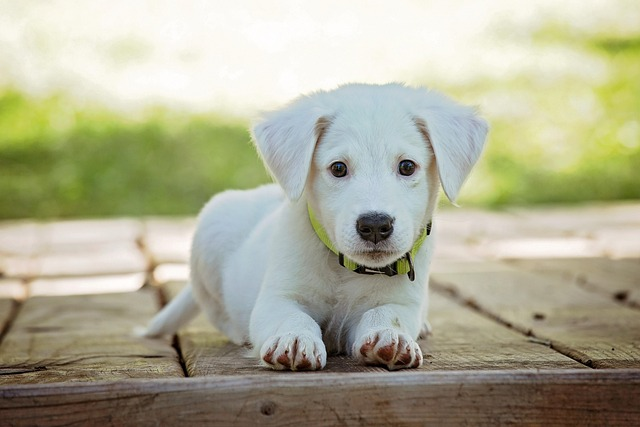

In [8]:
img_color = cv2.imread('./data/dog.jpg',cv2.IMREAD_COLOR) # 이미지 불러오기
img_gray = cv2.imread('./data/dog.jpg',cv2.IMREAD_GRAYSCALE) # 이미지 불러오기
img_unchanged = cv2.imread('./data/dog.jpg',cv2.IMREAD_UNCHANGED) # 이미지 불러오기

cv2_imshow(img_color) # 이미지 보여주기
cv2_imshow(img_gray) # 이미지 보여주기
cv2_imshow(img_unchanged) # 이미지 보여주기

cv2.waitKey(0) # 무한대기
cv2.destroyAllWindows() # opencv를 사용해서 열린창을 닫는 기능

In [17]:
%pwd

'/content/drive/MyDrive/2026_목포대학교_vision'

array([[239, 237, 236, ..., 223, 224, 224],
       [237, 235, 236, ..., 223, 223, 222],
       [235, 234, 235, ..., 223, 222, 221],
       ...,
       [ 42,  47,  51, ...,  50,  47,  47],
       [ 38,  41,  44, ...,  40,  37,  38],
       [ 40,  41,  43, ...,  44,  41,  42]], shape=(427, 640), dtype=uint8)
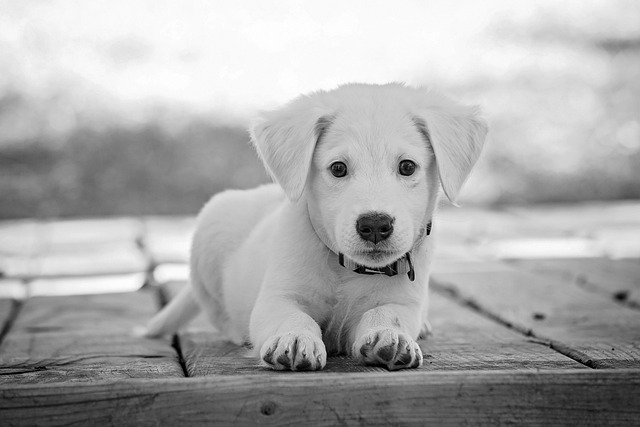

In [9]:
img_gray

#### cvtColor() - flag 정리
| 함수명     | 플래그 속성 명                        | 기능 설명                                                                 |
|------------|--------------------------------------|----------------------------------------------------------------------------|
| cvtColor() | cv2.COLOR_BGR2GRAY                   | BGR 색상 공간을 그레이스케일로 변환                                  |
| cvtColor() | cv2.COLOR_GRAY2BGR                   | 그레이스케일을 BGR 색상 공간으로 변환                                |
| cvtColor() | cv2.COLOR_BGR2RGB                    | BGR 색상 공간을 RGB 색상 공간으로 변환                               |
| cvtColor() | cv2.COLOR_RGB2BGR                    | RGB 색상 공간을 BGR 색상 공간으로 변환                               |
| cvtColor() | cv2.COLOR_BGR2HSV                    | BGR 색상 공간을 HSV 색상 공간으로 변환                               |
| cvtColor() | cv2.COLOR_RGB2HSV                    | RGB 색상 공간을 HSV 색상 공간으로 변환                               |
| cvtColor() | cv2.COLOR_HSV2BGR                    | HSV 색상 공간을 BGR 색상 공간으로 변환                               |
| cvtColor() | cv2.COLOR_HSV2RGB                    | HSV 색상 공간을 RGB 색상 공간으로 변환                               |

### 색상공간 변환
- 시각정인 정보는 색상에 따라 잘못된 정보를 보내주는 경우가 있다.
    - 밤에 색상을 볼 때 정확한 색상을 알지 못함 - 명도차이때문
    - 색상에 빛이 너무 강하게 비춰지면 정확한 색상이 안나옴 - 흰색이 섞여버려서 기본 색상을 못읽을 경우가 생김
    - 컬러는 너무 많은 정보를 가지고 있기 때문에 연산량이 많아 실시간 처리를 할 경우에는 많은 자원이 필요하다.
    - 상황에 따라 색상을 사용하지 않고 gray이미지로 변환해서 사용을 하는 경우가 많다.
    - gray 이미지 : 0~255로 된 픽셀로만 구성된 흑백 이미지로 0에 가까울 수록 검은색을 띄고 255에 가까울 수록 흰색을 띈다.

### 이진(Binary) 이미지 : 검정색과 흰색으로만 구성된 이미지
- 특정 패턴이나 물체의 윤곽을 감지
- 배경/물체 구별
- 텍스트 필터링 -> 검정색으로는 글자를 표현 -> 검정색에 대한 텍스트를 읽는 기술 (OCR)
- 뼈의 윤곽 / mri 스캔 종양 식별
- 자율 주행 시 장애물 / 차선 등 감지
- 제품 결함 및 불량품 식별 등 사용이 가능

### 이진 이미지 구성
- 이진화란 명암 영상 또는 이미지를 흑과 백만을 가진 이진 영상으로 변환하는 것을 의미
- 사용하는 이유에는 여러가지가 있지만 가장 중요한 이유는 어떤 경계값을 기준으로 이진화를 시키면 물체가 뚜렷하게 보여지기 때문
- 사용방법 : Grayscale이 적용된 이미지를 가지고 사용
    - 임계값 : 0과 1로 나누기 위한 기준값 (흑 / 백)
    - 임계값보다 픽셀값이 크면 백을 할당하고 아니면 흑을 할당
    - 임계값보다 픽셀값이 크면 흑을 할당하고 아니면 백을 할당

In [10]:
# 1. 폰트 설치
!sudo apt-get install -y fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 2. 세션 재시작 없이 맷플롯립에 폰트 강제 추가
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)

# 3. 폰트 설정 및 마이너스 기호 깨짐 방지
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

print("세션 재시작 없이 폰트 설정이 완료되었습니다!")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (6,348 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and

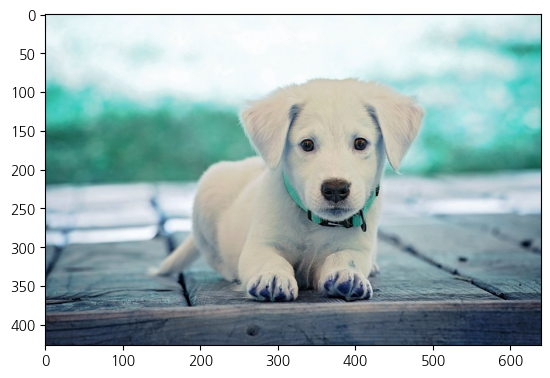

In [11]:
cv2.imread('./data/dog.jpg', cv2.IMREAD_COLOR)
plt.imshow(img)
plt.show()

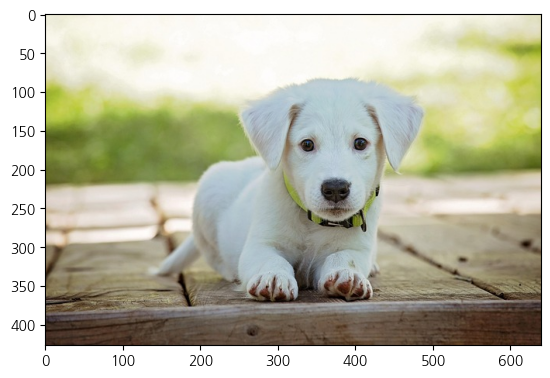

In [22]:
# 현재 불러온 순서는 BGR
# (imread는 기본적으로  BGR로 불러들인다)
cv2.imread('./data/dog.jpg', cv2.IMREAD_COLOR)
# bgr을 rgb로 변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

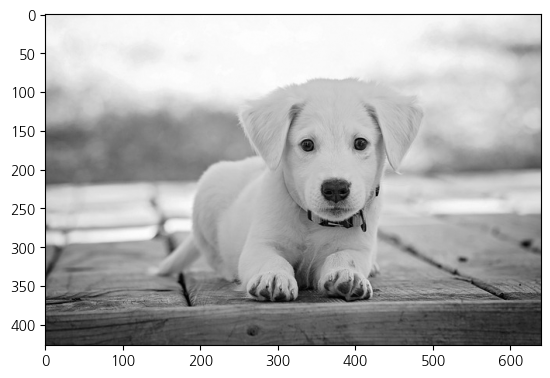

In [12]:
# 현재 불러온 순서는 BGR
# (imread는 기본적으로  BGR로 불러들인다)
cv2.imread('./data/dog.jpg', cv2.IMREAD_COLOR)
# bgr을 rgb로 변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # 데이터 변환
plt.imshow(img, cmap='gray') # 시각화렌더링
plt.show()

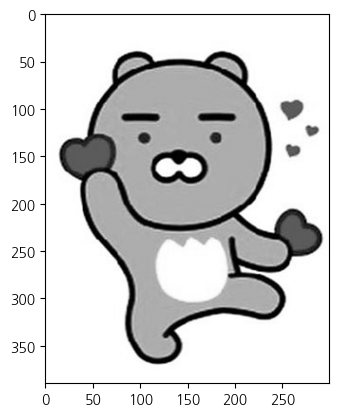

In [13]:
# 흑백이미지로 이미지 읽어오기
img = cv2.imread('./data/ryan.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray') # 색상정보를 grayscale에 맞도록 표현해 주세요
plt.show()


In [19]:
# cv2.threshold() :: 이미지 이진화(Thresholding) 함수
# 컴퓨터 비전 전처리 과정에서 이미지의 배경과 전경(객체)을 분리할 때 가장 기본적이고 빈번하게 쓰이는 핵심 기술

In [20]:
# 0~255 기준값:100,최대값:255
th_val,thr_img = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY)
# THRESH_BINARY : 기준점수보다 크면 최대값 할당 나머지는 0 할당
# THRESH_BINARY_INV : 기준점수보다 크면 0 할당 나머지는 255 할당

In [21]:
th_val

100.0

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(390, 300), dtype=uint8)
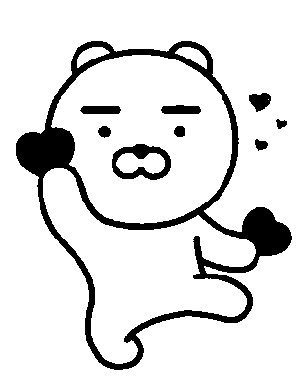

In [22]:
thr_img

In [34]:
th_val2,thr_img2 = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY_INV)

In [35]:
th_val2

100.0

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(390, 300), dtype=uint8)
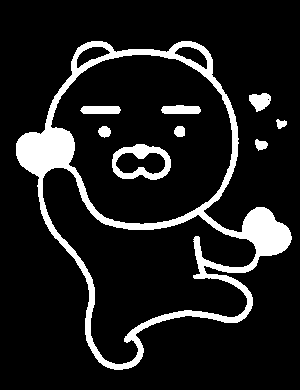

In [36]:
thr_img2

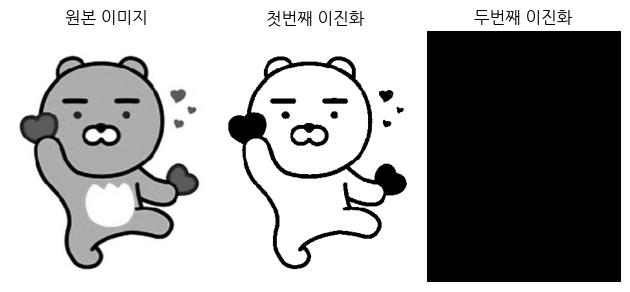

In [30]:
# 결과 화면
import matplotlib.pyplot as plt

# 첫번째 공간(왼쪽)
plt.subplot(1,3,1)
plt.axis('off') # 이미지 주변 축과 눈금 숨기기
plt.imshow(img, cmap='gray')
plt.title('원본 이미지')
# 두번째 공간
plt.subplot(1,3,2)
plt.axis('off') # 이미지 주변 축과 눈금 숨기기
plt.imshow(thr_img, cmap='gray')
plt.title('첫번째 이진화')
# 세번째 공간
plt.subplot(1,3,3)
plt.axis('off') # 이미지 주변 축과 눈금 숨기기
plt.imshow(thr_img2, cmap='gray')
plt.title('두번째 이진화')

plt.tight_layout() # 이미지 간격 자동 조절
plt.show()

### 이진이미지 변환
- 이진이미지를 변환할 때 임계값을 우리가 설정해서 사용했더니 값에 따라서 나오는 이미지가 달라지기 때문에 임계값에 따라서 받아오는 정보가 달라진다.
- 다시말해서 주관적인 값이 들어가기 때문에 사용자에 따라 같은 이미지를 사용하더라도 결과가 달라질 수 있다.

### 자동으로 임계값을 찾아주는 기능 적용해보기 : Otsu(오츠)의 이진화
- 노부유키 오츠에 의해 제안된 기능
- Otsu의 이진화는 이미지의 픽셀 값 분포를 분석하여 최적의 임계값을 자동으로 선택해서 이진화 진행

### Otsu의 이진화 방법
1. 히스토그램 분석
    - 이미지의 밝기 값의 히스토그램 계산을 진행
    - 히스토그램은 각 밝기 값이 이미지에서 몇 번 나타내는지를 나타내서 분석
2. 분산 최소화
    - Otsu의 알고리즘은 임계값을 기준으로 두 개의 클래스(배경과 객체)로 이미지를 분할
    - 최적의 임계값은 두 클래스 간의 분산이 최소가 되도록 선택
    - 이 방법을 통해 클래스 간의 차이가 최대가 되는 임계값을 설정
3. 임계값을 적용 : 찾은 최적의 임계값을 사용하여 이미지를 이진화 진행

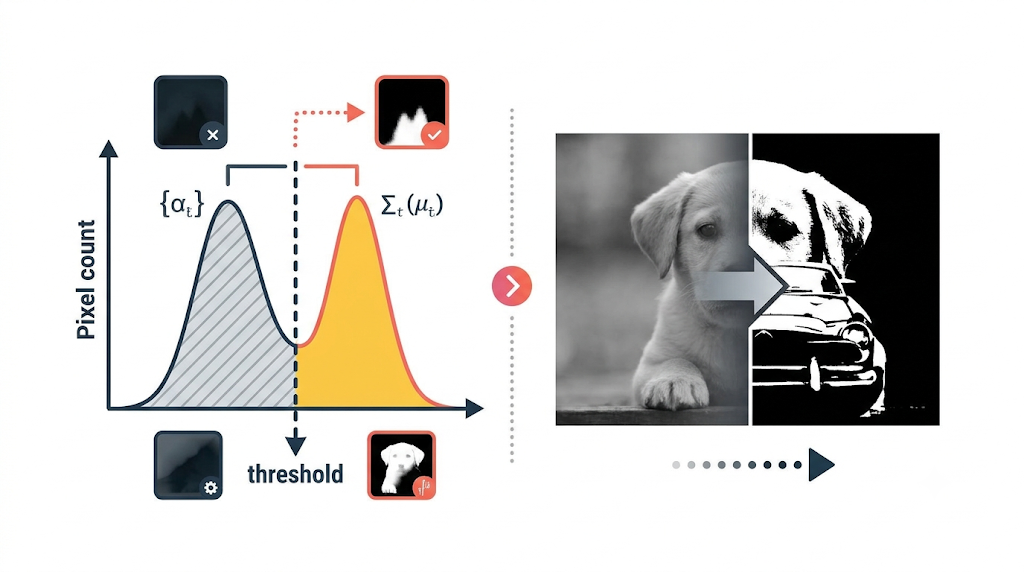

1. 히스토그램 분석 (픽셀 성적표 정리)
0(완전 검정)부터 255(완전 흰색)까지 각각의 밝기를 가진 픽셀이 도대체 몇 개씩 있는지 개수를 세어 표(히스토그램)로 만듭니다.

2. 분산 최소화 (가장 훌륭한 커트라인 찾기)
임의의 임계값을 기준으로 이미지를 '어두운 배경 그룹'과 '밝은 물체 그룹' 둘로 나눕니다. 이때 두 그룹의 평균 밝기 차이가 가장 극명하게 벌어지는 순간을 찾아, 그때의 값을 최적의 임계값으로 스스로 결정합니다.

3. 임계값 적용 (흑백 이미지로 변환)
최종적으로 찾아낸 최고의 임계값보다 밝은 픽셀은 흰색(255)으로, 어두운 픽셀은 검은색(0)으로 바꾸어 깔끔한 이진화 결과를 보여줍니다.

### Otsu방법을 수동으로 사용하여 임계값 찾아보기

### OpenCV에 내장되어있는 Otsu 이진화 함수를 활용하여 자동으로 임계값을 찾기

### ROI(관심영역, Region of Interest)
- 이미지 또는 영상 내에서 관심있는 일정 부분을 가지고 데이터를 사용하는 기술

### 텍스트 인식(OCR)
- OCR : 광학 문자 인식(Optical Character Recognition)
- 텍스트가 담긴 이미지를 기계가 읽을 수 있도록 변화하는 과정
    - EasyOCR
    - Naver Clova
    - Google Vision
    - AWS Textract
    - PaddleOCR
- 한국어를 인식하는지 안하는지도 다르고 유료인지 무료인지도 다르고 인식 방법도 조금씩 다르다.
- 속도차이, 사용방법 등 여러가지 차이점이 있기 때문에 꼭 사용전에 알아보고 사용하기!

### PaddleOCR
- PaddlePaddle 기반 오픈 소스 OCR 라이브러리
- 80개 이상의 언어를 지원
- 다양한 언어를 사용할 수 있고, 높은 정확도를 나타내며, 빠른 속도가 장점이다.
- 한국어를 사용할 때 아직 완벽하진 않음
- 모델이 여러가지가 있는데 경량모델도 지원

### OCR 사용

In [24]:
# 이미지 속의 텍스트를 인식하고 추출하는 데 사용되는 강력한 오픈소스 광학 문자 인식(OCR) 도구

In [25]:
!pip install paddleocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 16.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 19.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 51.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 55.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 78.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 74.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 72.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 40.0 MB/s  0:00:00
  Attempting uninstall: PyYAML
    Found existing installation: PyYAML 6.0.3
    Uninstalling PyYAML-6.0.3:
      Successfully uninstalled PyYAML-6.0.3
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: opencv-contrib-python
    Found existing installation: opencv-contrib-py

In [26]:
# PaddleOCR이 작동하기 위해 뼈대가 되는 딥러닝 프레임워크
!pip install paddlepaddle==3.2.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 189.3/189.3 MB 40.1 MB/s  0:00:04
  Attempting uninstall: opt_einsum
    Found existing installation: opt_einsum 3.4.0
    Uninstalling opt_einsum-3.4.0:
      Successfully uninstalled opt_einsum-3.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [paddlepaddle]


In [ ]:
import paddle
import paddleocr
import paddlex
import sys

print("Python:", sys.version)
print("Paddle:", paddle.__version__)
print("PaddleOCR:", paddleocr.__version__)
print("PaddleX:", paddlex.__version__)
print("GPU 사용 가능:", paddle.is_compiled_with_cuda())

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


In [ ]:
from paddleocr import PaddleOCR
import paddle

In [ ]:
!pwd

In [ ]:
# rec_text: 이미지에서 인식된 텍스트 문자열들이 담긴 리스트
# rec_score: 각 텍스트가 얼마나 정확한지 나타내는 신뢰도 점수(0~1 사이) 리스트
# dt_polys: 인식된 텍스트 영역의 바운딩 박스 꼭짓점 좌표들 리스트

### OCR 사용후 결과값
- 텍스트정보를 담은 곳의 좌표값 -> 좌표 리스트(numpy배열)
- 텍스트 정보 -> 인식된 문자가 담긴 리스트
- 신뢰도 -> 각 문자열 신뢰도를 담은 리스트

### OCR 사용 결과
- 우리가 사용한 모델은 경량화 된 모델이라 성능을 우선시 하기보단 속도측면과 사용자원을 최소화 한 모델이기 때문에 성능이 비교적 안나오는 모델일 수 있음
- 특히나 우리가 사용한 이미지는 이미지의 크기에 비해서 글자수가 너무 많아 글자의 크기가 작아서 제대로 된 텍스트 추출이 힘들 수 있음
- 따라서 이번에는 모델이 텍스트를 잘 인식할 수 있도록 글자의 크기가 이미지의 크기에 비례해 큰 이미지를 사용해서 OCR 사용을 해보자
- 자동차 번호판 이미지 인식을 진행하기

### 결과 시각화

In [ ]:
# NanumGothic

In [ ]:
import matplotlib.pyplot as plt
plt.rc('font', family='NanumGothic')